In [ ]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split
)

sns.set_theme(style="whitegrid", palette="deep")
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

RANDOM_STATE = 42

In [7]:
# Importing the dataset
Penguin_data = pd.read_csv("Penguin_Species_Prediction_Dataset.csv")

In [8]:
# Visualizing the top two rows
Penguin_data.head(2)

,species,island,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,41.1,18.4,195.0,3886.0,Female
1,Gentoo,Biscoe,50.0,15.4,217.0,4303.0,Male


In [9]:
# Checking the shape of the dataframe
Penguin_data.shape

(1000, 7)

In [10]:
# Checking datatype and null values in each column
Penguin_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            1000 non-null   str    
 1   island             1000 non-null   str    
 2   culmen_length_mm   990 non-null    float64
 3   culmen_depth_mm    990 non-null    float64
 4   flipper_length_mm  990 non-null    float64
 5   body_mass_g        990 non-null    float64
 6   sex                990 non-null    str    
dtypes: float64(4), str(3)
memory usage: 54.8 KB


In [11]:
# Checking statistical distribution for each column
Penguin_data.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
species,1000,3,Adelie,461,NaN,NaN,NaN,NaN,NaN,NaN,NaN
island,1000,3,Dream,527,NaN,NaN,NaN,NaN,NaN,NaN,NaN
culmen_length_mm,990.0,NaN,NaN,NaN,43.817778,5.309985,32.4,39.0,43.8,48.3,56.0
culmen_depth_mm,990.0,NaN,NaN,NaN,17.335556,1.779057,13.0,15.8,17.8,18.7,21.4
flipper_length_mm,990.0,NaN,NaN,NaN,199.224242,13.17166,175.0,189.0,195.0,212.0,235.0
body_mass_g,990.0,NaN,NaN,NaN,4103.311111,705.334794,2830.0,3586.0,3882.0,4587.0,6317.0
sex,990,2,Male,528,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [12]:
# Count of each species
Penguin_data.species.value_counts()

species
Adelie       461
Gentoo       288
Chinstrap    251
Name: count, dtype: int64

In [13]:
# Count of each island
Penguin_data.island.value_counts()

island
Dream        527
Biscoe       302
Torgersen    171
Name: count, dtype: int64

In [14]:
# Count of number of null values in each column
Penguin_data.isnull().sum()

species               0
island                0
culmen_length_mm     10
culmen_depth_mm      10
flipper_length_mm    10
body_mass_g          10
sex                  10
dtype: int64

In [15]:
# dropping null values
Penguin_data = Penguin_data.dropna()

In [16]:
# checking final shape after drop
Penguin_data.shape

(951, 7)

In [17]:
# Checking for duplicates
Penguin_data.duplicated().sum()

np.int64(0)

,count
species,
Adelie,438
Gentoo,273
Chinstrap,240


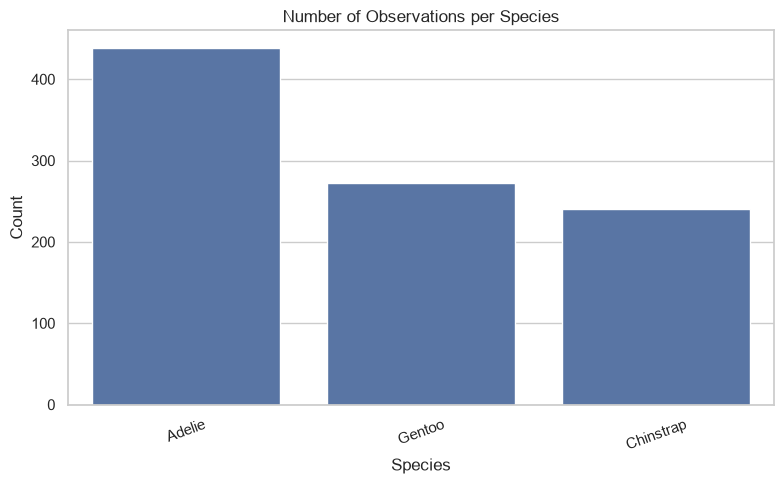

In [18]:
# Performing exploratory data analysis on the data
# First checking the distribution of each species
species_counts = Penguin_data['species'].value_counts()

display(species_counts.to_frame("count"))

plt.figure(figsize=(8, 5))
sns.countplot(data=Penguin_data, x='species', order=species_counts.index)
plt.title("Number of Observations per Species")
plt.xlabel("Species")
plt.ylabel("Count")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [19]:
# displays the percentage distribution of each species
display(
    (Penguin_data['species'].value_counts(normalize=True) * 100)
    .round(2)
    .rename("percentage")
    .to_frame()
)

,percentage
species,
Adelie,46.06
Gentoo,28.71
Chinstrap,25.24


In [21]:
# select the columns which is numerical for input and then split the other in to categorical columns and spcies target
Numerical_cols = ['culmen_length_mm','culmen_depth_mm','flipper_length_mm','body_mass_g']
catagorical_cols = ['island','sex']
Penguin_Species = ['Adelie','Gentoo','Chinstrap']

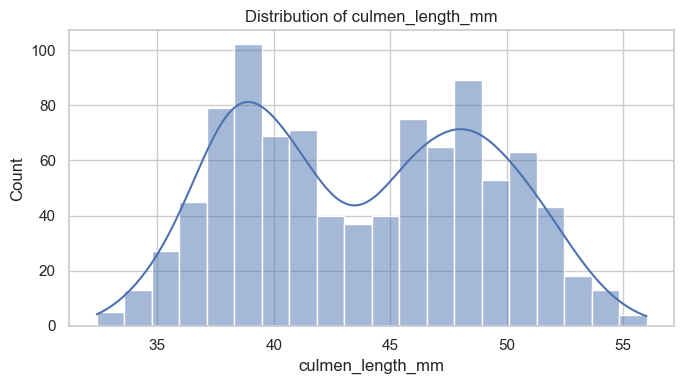

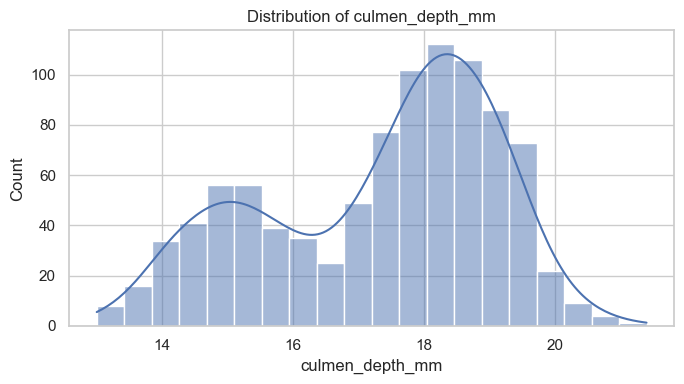

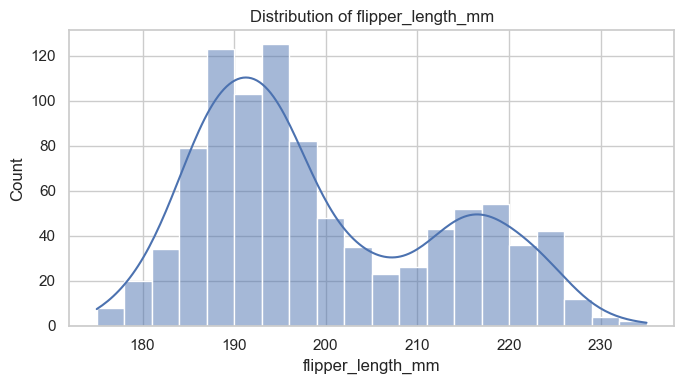

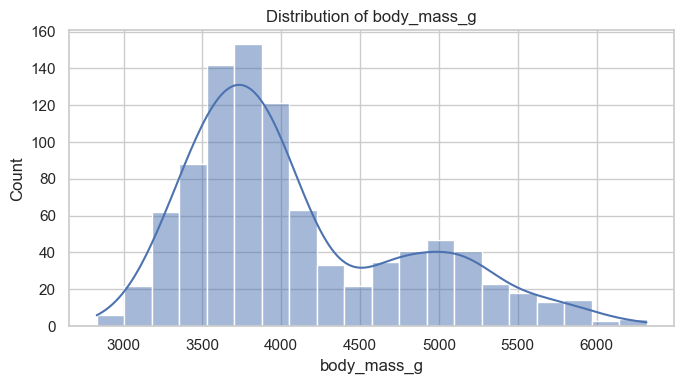

In [ ]:
# performing a visualization on the distribution of each of the numerical data in a histogram.
# all the graph shows a binomial distribution.
for col in Numerical_cols:
    fig, ax = plt.subplots(figsize=(7, 4))

    sns.histplot(
        data=Penguin_data, x=col, kde=True, bins=20, ax=ax
    )

    ax.set_title(f"Distribution of {col}")
    plt.tight_layout()
    plt.show()

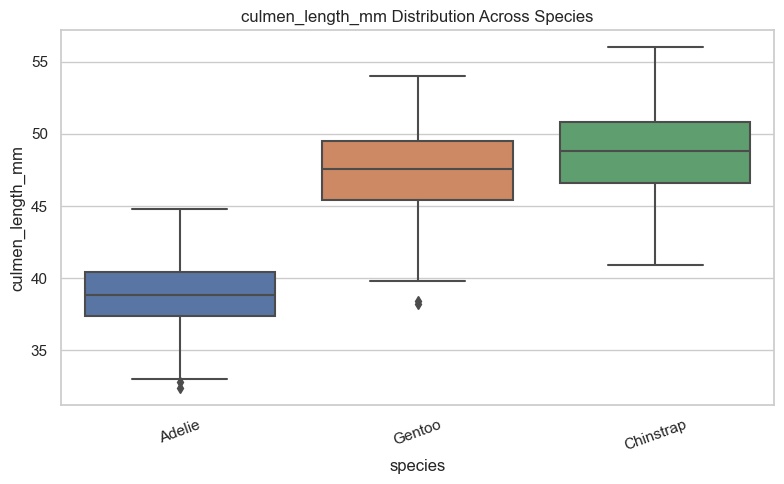

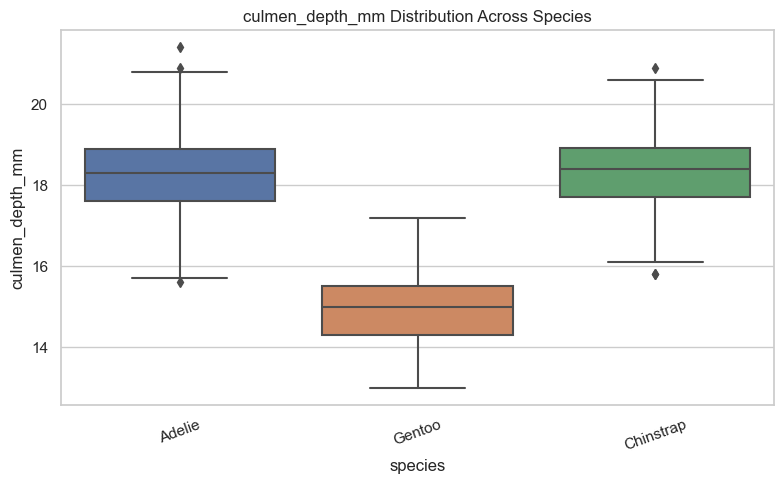

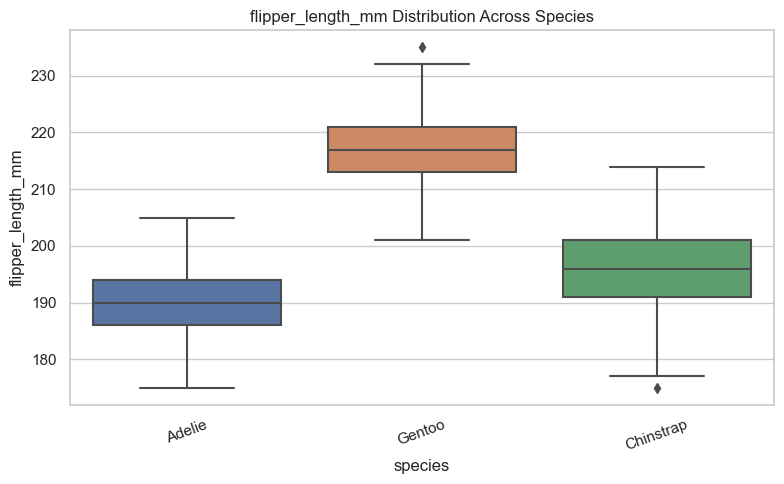

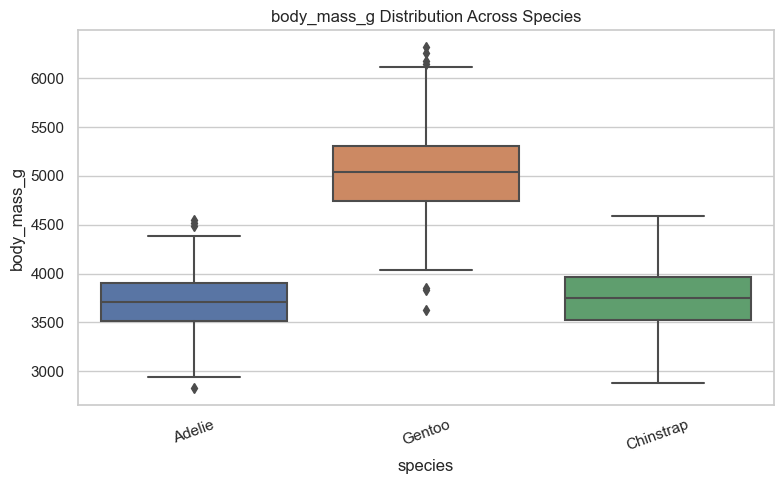

In [ ]:
# we decided to use a box plot representation to see how well we can distinguish the species with respect
# to it's 4 numerical feature columns. The graph shows that each feature shows clear difference between
# each species which could really help in the model to figure out patterns in classification.
for col in Numerical_cols:
    plt.figure(figsize=(8, 5))

    sns.boxplot(data=Penguin_data, x='species', y=col)

    plt.title(f"{col} Distribution Across Species")
    plt.xticks(rotation=20)
    plt.tight_layout()
    plt.show()

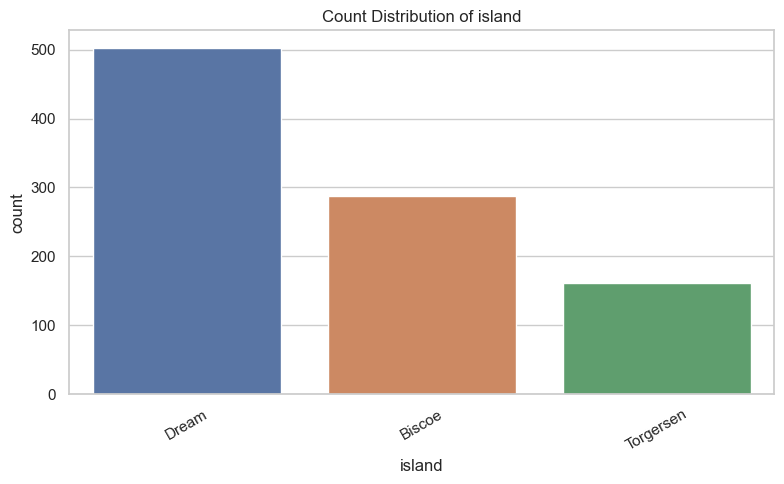

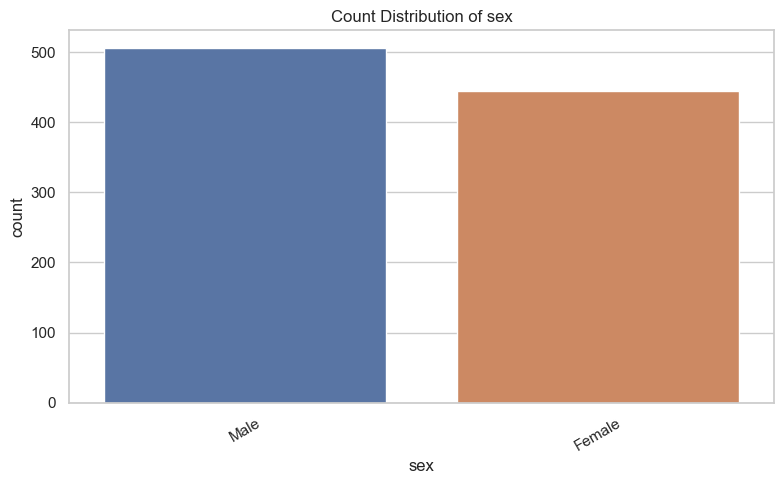

In [ ]:
# These graphs shows the distribution of the categorical data in a bar chart for both island and sex. The
# distribution shows that there is more penguins in Dream island and there are more male than female 
# penguins
for col in catagorical_cols:
    plt.figure(figsize=(8, 5))

    sns.countplot(
        data=Penguin_data, x=col,
        order=Penguin_data[col].value_counts().index
    )

    plt.title(f"Count Distribution of {col}")
    plt.xticks(rotation=30)
    plt.tight_layout()
    plt.show()

species,Adelie,Chinstrap,Gentoo,All
island,,,,
Biscoe,14,0,273,287
Dream,263,240,0,503
Torgersen,161,0,0,161
All,438,240,273,951


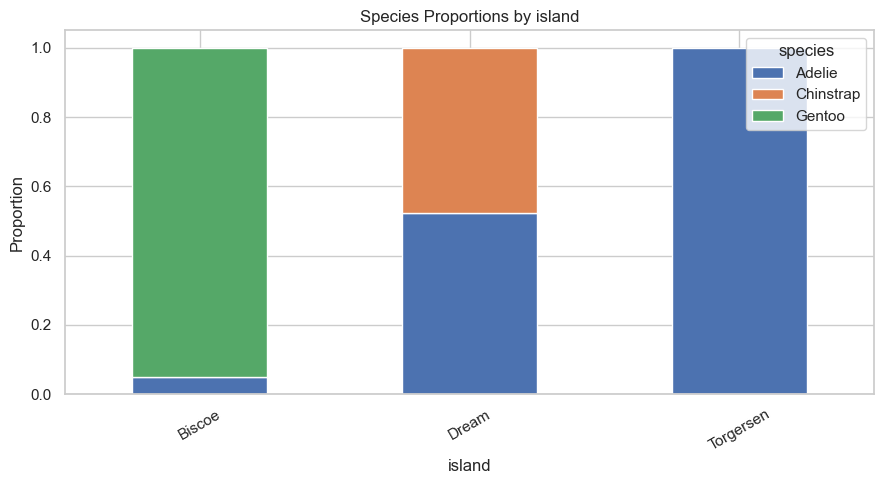

species,Adelie,Chinstrap,Gentoo,All
sex,,,,
Female,224,115,106,445
Male,214,125,167,506
All,438,240,273,951


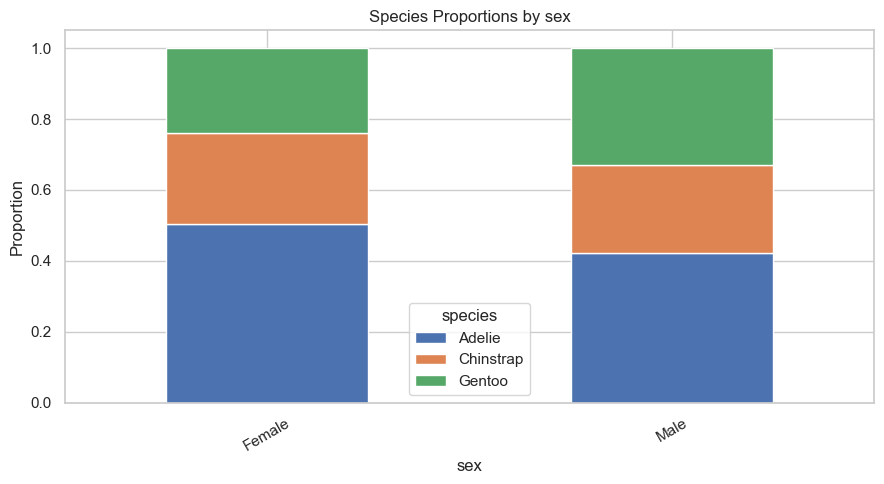

In [ ]:
# These graphs shows a stacked bar graph of the proportion of species in each island and gender. The
# first graph shows that the island Torgersen consists of only Adelie species which is a good thing
# for the model as it would predict with ease when the island is Torgersen. For the gender, we could
# not see a very significant proportion difference hence the model might struggle to predict the gender
# given then island and species.
for col in catagorical_cols:
    display(pd.crosstab(Penguin_data[col], Penguin_data['species'], margins=True))

    pd.crosstab(
        Penguin_data[col], Penguin_data['species'], normalize="index"
    ).plot(kind="bar", stacked=True, figsize=(9, 5))

    plt.title(f"Species Proportions by {col}")
    plt.ylabel("Proportion")
    plt.xticks(rotation=30)
    plt.tight_layout()
    plt.show()

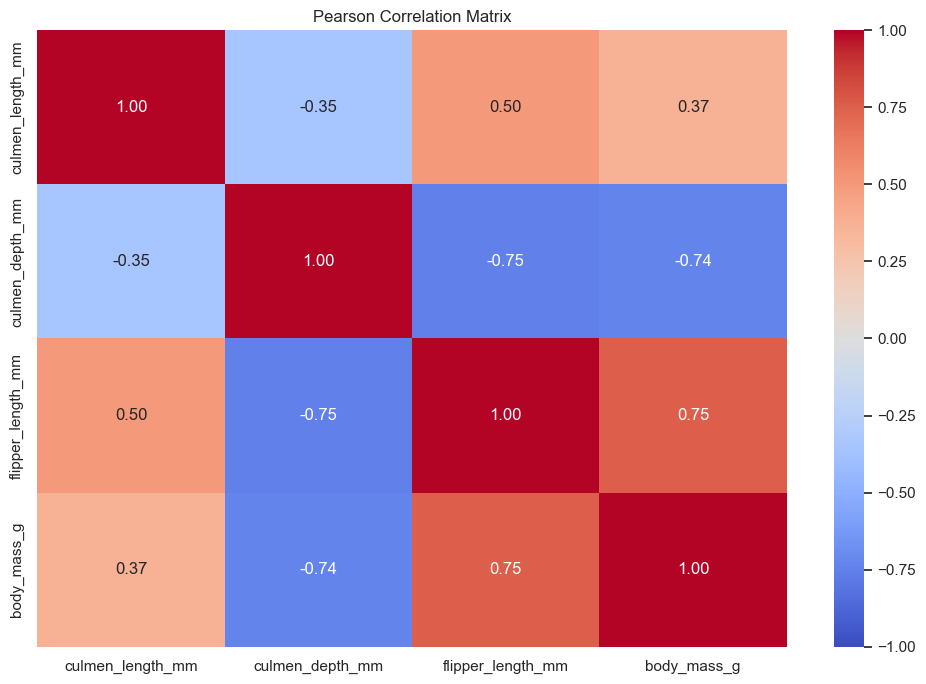

In [ ]:
# This is a Pearson Correlation matrix done to see how each column of the numerical feature correlate
# with each other. It is clear that other than culmnen length, other feature correlates well with each
# other feature.
corr = Penguin_data[Numerical_cols].corr(method="pearson")

plt.figure(figsize=(10, 7))
sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1
)

plt.title("Pearson Correlation Matrix")
plt.tight_layout()
plt.show()

In [ ]:
# This code checks the t-test for each species with the distribution of the genders. We wanted to see
# how significantly different botht the gender is different from each other with the distribution data.
# Our null hypothesis is that both the gender is significantly not different in measurement while the
# alternative hypothesis states that both gender has significantly different distribution and measurements.
# The results shows that the p-value is more than the alpha value of 5% and all the values is more than
# 0.05 hence we fail to reject the null hypothesis. This tells us that the model might not be good at
# predicting the gender.
from scipy.stats import ttest_ind
from statsmodels.stats.multitest import multipletests

Numerical_cols = [
    'culmen_length_mm',
    'culmen_depth_mm',
    'flipper_length_mm',
    'body_mass_g'
]

Target = 'species'
Sex = 'sex'

# Make sex labels consistent
analysis_df = Penguin_data.copy()
analysis_df[Sex] = analysis_df[Sex].astype('string').str.strip().str.lower()

results = []

# Test male vs female within each species
for species in Penguin_Species:

    species_df = analysis_df[analysis_df[Target] == species]

    for col in Numerical_cols:

        male = species_df.loc[
            species_df[Sex] == 'male', col
        ].dropna()

        female = species_df.loc[
            species_df[Sex] == 'female', col
        ].dropna()

        # Need at least two observations per group
        if len(male) < 2 or len(female) < 2:
            continue

        # Welch's independent two-sample t-test
        t_stat, p_value = ttest_ind(
            male,
            female,
            equal_var=False,
            alternative='two-sided'
        )

        results.append({
            'Species': species,
            'Measurement': col,
            'Male_N': len(male),
            'Female_N': len(female),
            'Male_Mean': male.mean(),
            'Female_Mean': female.mean(),
            'Mean_Difference': male.mean() - female.mean(),
            'T_Statistic': t_stat,
            'P_Value': p_value
        })

results_df = pd.DataFrame(results)

# Correct for multiple comparisons using Benjamini-Hochberg
if not results_df.empty:
    results_df['Adjusted_P_Value'] = multipletests(
        results_df['P_Value'],
        method='fdr_bh'
    )[1]

    results_df['Significant'] = (
        results_df['Adjusted_P_Value'] < 0.05
    )

    display(results_df.round(4))
else:
    print("No valid comparisons. Check the sex labels and missing values.")


,Species,Measurement,Male_N,Female_N,Male_Mean,Female_Mean,Mean_Difference,T_Statistic,P_Value,Adjusted_P_Value,Significant
0,Adelie,culmen_length_mm,214,224,39.0327,38.6710,0.3617,1.7093,0.0881,0.4167,False
1,Adelie,culmen_depth_mm,214,224,18.2126,18.3094,-0.0968,-1.0211,0.3078,0.5778,False
2,Adelie,flipper_length_mm,214,224,190.1121,189.6116,0.5005,0.9610,0.3371,0.5778,False
3,Adelie,body_mass_g,214,224,3731.4439,3671.7411,59.7029,2.1039,0.0360,0.4167,False
4,Gentoo,culmen_length_mm,167,106,47.3575,47.4481,-0.0906,-0.2408,0.8100,0.8836,False
5,Gentoo,culmen_depth_mm,167,106,14.9916,14.8538,0.1378,1.3652,0.1736,0.4167,False
6,Gentoo,flipper_length_mm,167,106,217.5090,217.0943,0.4146,0.5876,0.5574,0.7432,False
7,Gentoo,body_mass_g,167,106,5036.5329,5077.3962,-40.8633,-0.7164,0.4745,0.7117,False
8,Chinstrap,culmen_length_mm,125,115,48.8024,48.9026,-0.1002,-0.2733,0.7848,0.8836,False
9,Chinstrap,culmen_depth_mm,125,115,18.4072,18.2435,0.1637,1.4397,0.1513,0.4167,False


In [ ]:

# Here we did a bit of data augmentation by adding two new columns. culmen_length_depth_ratio and
# mass_per_flipper by calculating the ratio of these columns which could help the model predict better
# with these extra informations.
Penguin_fe = Penguin_data.copy()

# 1. Culmen length-to-depth ratio
if {"culmen_length_mm", "culmen_depth_mm"}.issubset(Penguin_fe.columns):
    Penguin_fe["culmen_length_depth_ratio"] = (
        Penguin_fe["culmen_length_mm"] /
        Penguin_fe["culmen_depth_mm"].replace(0, np.nan)
    )

# # 2. Convert body mass from grams to kilograms

    # 3. Body mass per millimetre of flipper length
    Penguin_fe["mass_per_flipper_mm"] = (
        Penguin_fe["body_mass_g"] /
        Penguin_fe["flipper_length_mm"].replace(0, np.nan)
    )

display(Penguin_fe.head())


,species,island,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex,culmen_length_depth_ratio,mass_per_flipper_mm
0,Adelie,Torgersen,41.1,18.4,195.0,3886.0,Female,2.233696,19.928205
1,Gentoo,Biscoe,50.0,15.4,217.0,4303.0,Male,3.246753,19.829493
2,Gentoo,Biscoe,50.0,15.1,220.0,4954.0,Female,3.311258,22.518182
3,Chinstrap,Dream,48.7,19.0,196.0,3739.0,Male,2.563158,19.076531
4,Adelie,Dream,39.0,17.8,187.0,3607.0,Male,2.191011,19.288770


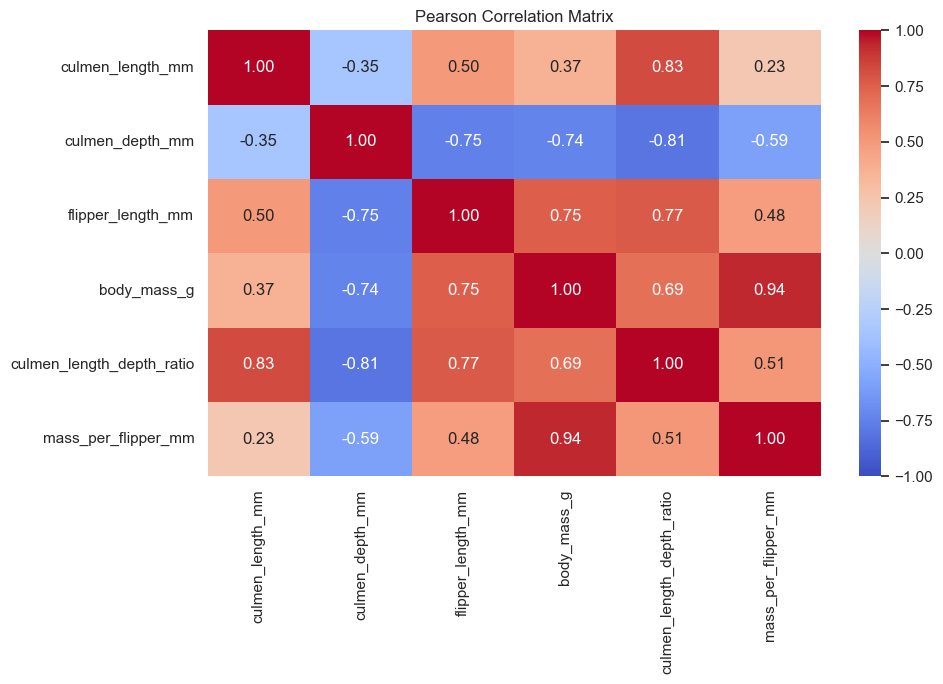

In [ ]:
# now we plot a correlation matrix with the new columns and this shows that the new columns does
# correlate well with other feature columns
Numerical_cols_fe = ['culmen_length_mm','culmen_depth_mm','flipper_length_mm','body_mass_g','culmen_length_depth_ratio','mass_per_flipper_mm']
corr = Penguin_fe[Numerical_cols_fe].corr(method="pearson")

plt.figure(figsize=(10, 7))
sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1
)

plt.title("Pearson Correlation Matrix")
plt.tight_layout()
plt.show()

In [ ]:

# we start preparing the data for training. We excluded the data augmented columns as we felt that the
# current features are good enough to generalize the data.

# Define columns
Numerical_cols = [
    'culmen_length_mm',
    'culmen_depth_mm',
    'flipper_length_mm',
    'body_mass_g'
]

Categorical_cols = ['sex', 'island']
Target = 'species'

### This is the model code on the data augmented entires so this column is commented out as we wont be
### using this. But this is a reference to what we had done for the data if we include it.
# # Separate features and target
# X = Penguin_data[Numerical_cols + Categorical_cols]
# y = Penguin_data[[Target]]

# # Preprocess numerical and categorical features
# preprocessor = ColumnTransformer(
#     transformers=[
#         ('num', StandardScaler(), Numerical_cols),
#         ('cat', OneHotEncoder(handle_unknown='ignore',
#                               sparse_output=False), Categorical_cols)
#     ]
# )

# # Transform features
# X_processed = preprocessor.fit_transform(X)

# # One-hot encode the target column
# target_encoder = OneHotEncoder(sparse_output=False)
# y_encoded = target_encoder.fit_transform(y)

# # Convert transformed features into DataFrames
# X_processed_df = pd.DataFrame(
#     X_processed,
#     columns=preprocessor.get_feature_names_out(),
#     index=X.index
# )

# y_encoded_df = pd.DataFrame(
#     y_encoded,
#     columns=target_encoder.get_feature_names_out([Target]),
#     index=y.index
# )

# print("Processed features:")
# display(X_processed_df.head())

# print("One-hot encoded target:")
# display(y_encoded_df.head())


In [134]:
# Separate features and original target labels
X = Penguin_data[Numerical_cols + Categorical_cols]
y = Penguin_data[Target]

# Stratified train-test split (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=4,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

# Check species proportions
print("\nTraining set species proportions:")
display(y_train.value_counts(normalize=True).sort_index())

print("\nTesting set species proportions:")
display(y_test.value_counts(normalize=True).sort_index())


Training features: (760, 6)
Testing features: (191, 6)
Training target: (760,)
Testing target: (191,)

Training set species proportions:


Adelie       0.460526
Chinstrap    0.252632
Gentoo       0.286842
Name: species, dtype: float64


Testing set species proportions:


Adelie       0.460733
Chinstrap    0.251309
Gentoo       0.287958
Name: species, dtype: float64

In [ ]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Feature preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), Numerical_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore',
                              sparse_output=False), Categorical_cols)
    ]
)

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)


print("Processed X_train:", X_train_processed.shape)
print("Processed X_test:", X_test_processed.shape)


Processed X_train: (760, 9)
Processed X_test: (191, 9)
Encoded y_train: (760, 3)
Encoded y_test: (191, 3)


In [ ]:
# perform label encoding
import pandas as pd

from sklearn.svm import SVC
from xgboost import XGBClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

In [ ]:
# converts text target labels into integer ID

from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()

y_train_labels = label_encoder.fit_transform(
    y_train.astype(str)
)

y_test_labels = label_encoder.transform(
    y_test.astype(str)
)

print("Species mapping:")

for i, species in enumerate(label_encoder.classes_):
    print(f"{species} = {i}")


Species mapping:
Adelie = 0
Chinstrap = 1
Gentoo = 2


In [ ]:
# define the models
models = {
    "SVC": SVC(
        C=1.0,
        kernel="rbf",
        random_state=42
    ),

    "xgb_model" : XGBClassifier(
        n_estimators=100,
        max_depth=4,
        learning_rate=0.1,
        objective="multi:softprob",
        num_class=len(label_encoder.classes_),
        eval_metric="mlogloss",
        random_state=42
    ),

    "KNN": KNeighborsClassifier(
        n_neighbors=5,
        weights="uniform",
        metric="minkowski"
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42
    )
}

results = []
trained_models = {}

for name, model in models.items():

    # Train the model
    model.fit(X_train_processed, y_train_labels)

    # Predict the test set
    y_pred = model.predict(X_test_processed)

    # Save the trained model
    trained_models[name] = model

    # Evaluate performance
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test_labels, y_pred),
        "Precision": precision_score(
            y_test_labels, y_pred,
            average="weighted", zero_division=0
        ),
        "Recall": recall_score(
            y_test_labels, y_pred,
            average="weighted", zero_division=0
        ),
        "F1_Score": f1_score(
            y_test_labels, y_pred,
            average="weighted", zero_division=0
        )
    })

results_df = pd.DataFrame(results)

display(
    results_df.sort_values(
        by="F1_Score",
        ascending=False
    ).reset_index(drop=True).round(4)
)


,Model,Accuracy,Precision,Recall,F1_Score
0,SVC,1.0000,1.0000,1.0000,1.0000
1,xgb_model,1.0000,1.0000,1.0000,1.0000
2,KNN,1.0000,1.0000,1.0000,1.0000
3,Random Forest,0.9895,0.9898,0.9895,0.9895



SPECIES - CLASSIFICATION REPORT: SVC
              precision    recall  f1-score   support

      Adelie       1.00      1.00      1.00        88
   Chinstrap       1.00      1.00      1.00        48
      Gentoo       1.00      1.00      1.00        55

    accuracy                           1.00       191
   macro avg       1.00      1.00      1.00       191
weighted avg       1.00      1.00      1.00       191


SPECIES - CONFUSION MATRIX: SVC


,Predicted Adelie,Predicted Chinstrap,Predicted Gentoo
Actual Adelie,88,0,0
Actual Chinstrap,0,48,0
Actual Gentoo,0,0,55


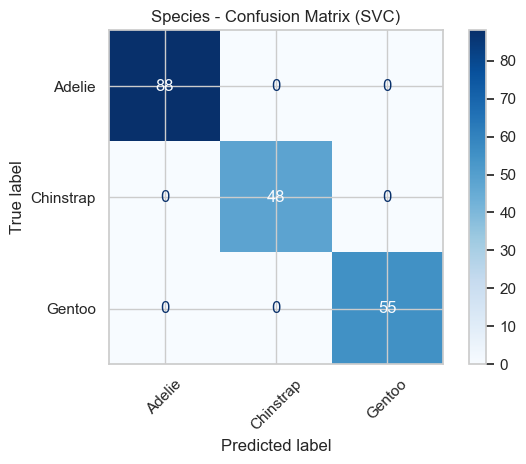


SPECIES - CLASSIFICATION REPORT: xgb_model
              precision    recall  f1-score   support

      Adelie       1.00      1.00      1.00        88
   Chinstrap       1.00      1.00      1.00        48
      Gentoo       1.00      1.00      1.00        55

    accuracy                           1.00       191
   macro avg       1.00      1.00      1.00       191
weighted avg       1.00      1.00      1.00       191


SPECIES - CONFUSION MATRIX: xgb_model


,Predicted Adelie,Predicted Chinstrap,Predicted Gentoo
Actual Adelie,88,0,0
Actual Chinstrap,0,48,0
Actual Gentoo,0,0,55


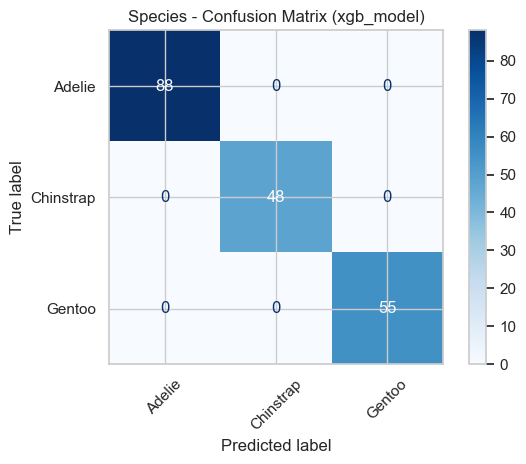


SPECIES - CLASSIFICATION REPORT: KNN
              precision    recall  f1-score   support

      Adelie       1.00      1.00      1.00        88
   Chinstrap       1.00      1.00      1.00        48
      Gentoo       1.00      1.00      1.00        55

    accuracy                           1.00       191
   macro avg       1.00      1.00      1.00       191
weighted avg       1.00      1.00      1.00       191


SPECIES - CONFUSION MATRIX: KNN


,Predicted Adelie,Predicted Chinstrap,Predicted Gentoo
Actual Adelie,88,0,0
Actual Chinstrap,0,48,0
Actual Gentoo,0,0,55


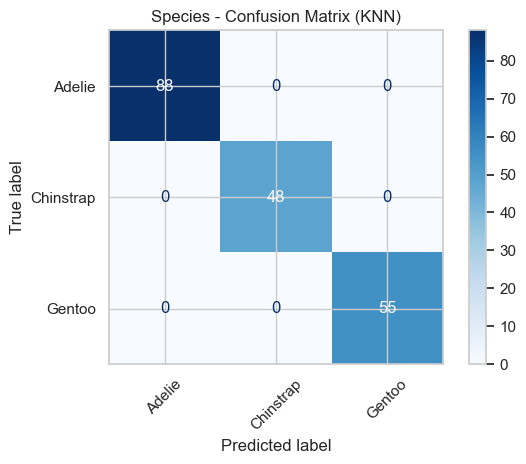


SPECIES - CLASSIFICATION REPORT: Random Forest
              precision    recall  f1-score   support

      Adelie       0.98      1.00      0.99        88
   Chinstrap       1.00      0.96      0.98        48
      Gentoo       1.00      1.00      1.00        55

    accuracy                           0.99       191
   macro avg       0.99      0.99      0.99       191
weighted avg       0.99      0.99      0.99       191


SPECIES - CONFUSION MATRIX: Random Forest


,Predicted Adelie,Predicted Chinstrap,Predicted Gentoo
Actual Adelie,88,0,0
Actual Chinstrap,2,46,0
Actual Gentoo,0,0,55


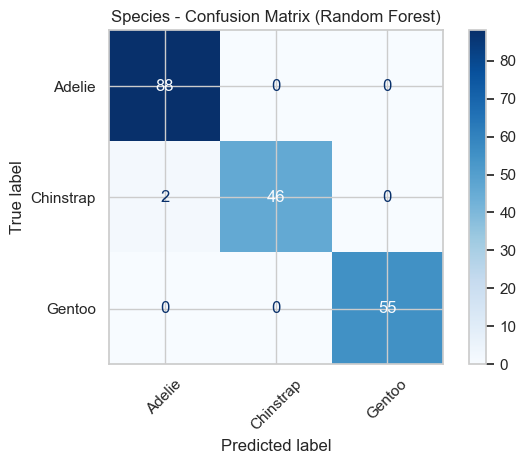

In [ ]:

# making the classification report and evaluation matrix.
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# Use the existing trained Species models
class_names = label_encoder.classes_
class_labels = np.arange(len(class_names))

for name, model in trained_models.items():
    y_pred = model.predict(X_test_processed)

    print(f"\n{'=' * 50}")
    print(f"SPECIES - CLASSIFICATION REPORT: {name}")
    print("=" * 50)

    print(classification_report(
        y_test_labels,
        y_pred,
        labels=class_labels,
        target_names=class_names,
        zero_division=0
    ))

    cm = confusion_matrix(
        y_test_labels,
        y_pred,
        labels=class_labels
    )

    cm_df = pd.DataFrame(
        cm,
        index=[f"Actual {c}" for c in class_names],
        columns=[f"Predicted {c}" for c in class_names]
    )

    print(f"\nSPECIES - CONFUSION MATRIX: {name}")
    display(cm_df)

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=class_names
    )
    disp.plot(cmap="Blues", values_format="d")
    plt.title(f"Species - Confusion Matrix ({name})")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()


In [ ]:
## Predicting Island
# now we do the same with island prediction excluding the data augmented columns. The code is commented
# out for reference.

# Define columns
Numerical_cols = [
    'culmen_length_mm',
    'culmen_depth_mm',
    'flipper_length_mm',
    'body_mass_g'
]

Categorical_cols = ['sex', 'species']
Target = 'island'

# # Separate features and target
# X = Penguin_data[Numerical_cols + Categorical_cols]
# y = Penguin_data[[Target]]

# # Preprocess numerical and categorical features
# preprocessor = ColumnTransformer(
#     transformers=[
#         ('num', StandardScaler(), Numerical_cols),
#         ('cat', OneHotEncoder(handle_unknown='ignore',
#                               sparse_output=False), Categorical_cols)
#     ]
# )

# # Transform features
# X_processed = preprocessor.fit_transform(X)

# # One-hot encode the target column
# target_encoder = OneHotEncoder(sparse_output=False)
# y_encoded = target_encoder.fit_transform(y)

# # Convert transformed features into DataFrames
# X_processed_df = pd.DataFrame(
#     X_processed,
#     columns=preprocessor.get_feature_names_out(),
#     index=X.index
# )

# y_encoded_df = pd.DataFrame(
#     y_encoded,
#     columns=target_encoder.get_feature_names_out([Target]),
#     index=y.index
# )

# print("Processed features:")
# display(X_processed_df.head())

# print("One-hot encoded target:")
# display(y_encoded_df.head())


In [142]:
# Separate features and original target labels
X = Penguin_data[Numerical_cols + Categorical_cols]
y = Penguin_data[Target]

# Stratified train-test split (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=4,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

# Check species proportions
print("\nTraining set species proportions:")
display(y_train.value_counts(normalize=True).sort_index())

print("\nTesting set species proportions:")
display(y_test.value_counts(normalize=True).sort_index())


Training features: (760, 6)
Testing features: (191, 6)
Training target: (760,)
Testing target: (191,)

Training set species proportions:


Biscoe       0.301316
Dream        0.528947
Torgersen    0.169737
Name: island, dtype: float64


Testing set species proportions:


Biscoe       0.303665
Dream        0.528796
Torgersen    0.167539
Name: island, dtype: float64

In [ ]:

# Feature preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), Numerical_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore',
                              sparse_output=False), Categorical_cols)
    ]
)

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)


print("Processed X_train:", X_train_processed.shape)
print("Processed X_test:", X_test_processed.shape)


Processed X_train: (760, 9)
Processed X_test: (191, 9)
Encoded y_train: (760, 3)
Encoded y_test: (191, 3)


In [145]:

label_encoder = LabelEncoder()

y_train_labels = label_encoder.fit_transform(
    y_train.astype(str)
)

y_test_labels = label_encoder.transform(
    y_test.astype(str)
)

print("Island mapping:")

for i, island in enumerate(label_encoder.classes_):
    print(f"{island} = {i}")


Island mapping:
Biscoe = 0
Dream = 1
Torgersen = 2


In [ ]:
# defining the model
models = {
    "SVC": SVC(
        C=1.0,
        kernel="rbf",
        random_state=42
    ),

    "xgb_model" : XGBClassifier(
        n_estimators=100,
        max_depth=4,
        learning_rate=0.1,
        objective="multi:softprob",
        num_class=len(label_encoder.classes_),
        eval_metric="mlogloss",
        random_state=42
    ),

    "KNN": KNeighborsClassifier(
        n_neighbors=5,
        weights="uniform",
        metric="minkowski"
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42
    )
}

results = []
trained_models = {}

for name, model in models.items():

    # Train the model
    model.fit(X_train_processed, y_train_labels)

    # Predict the test set
    y_pred = model.predict(X_test_processed)

    # Save the trained model
    trained_models[name] = model

    # Evaluate performance
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test_labels, y_pred),
        "Precision": precision_score(
            y_test_labels, y_pred,
            average="weighted", zero_division=0
        ),
        "Recall": recall_score(
            y_test_labels, y_pred,
            average="weighted", zero_division=0
        ),
        "F1_Score": f1_score(
            y_test_labels, y_pred,
            average="weighted", zero_division=0
        )
    })

results_df = pd.DataFrame(results)

display(
    results_df.sort_values(
        by="F1_Score",
        ascending=False
    ).reset_index(drop=True).round(4)
)


,Model,Accuracy,Precision,Recall,F1_Score
0,KNN,0.8010,0.7858,0.8010,0.7874
1,SVC,0.8115,0.6935,0.8115,0.7416
2,xgb_model,0.7539,0.7310,0.7539,0.7387
3,Random Forest,0.7592,0.7275,0.7592,0.7379



ISLAND - CLASSIFICATION REPORT: SVC
              precision    recall  f1-score   support

      Biscoe       1.00      0.93      0.96        58
       Dream       0.74      1.00      0.85       101
   Torgersen       0.00      0.00      0.00        32

    accuracy                           0.81       191
   macro avg       0.58      0.64      0.60       191
weighted avg       0.69      0.81      0.74       191


ISLAND - CONFUSION MATRIX: SVC


,Predicted Biscoe,Predicted Dream,Predicted Torgersen
Actual Biscoe,54,4,0
Actual Dream,0,101,0
Actual Torgersen,0,32,0


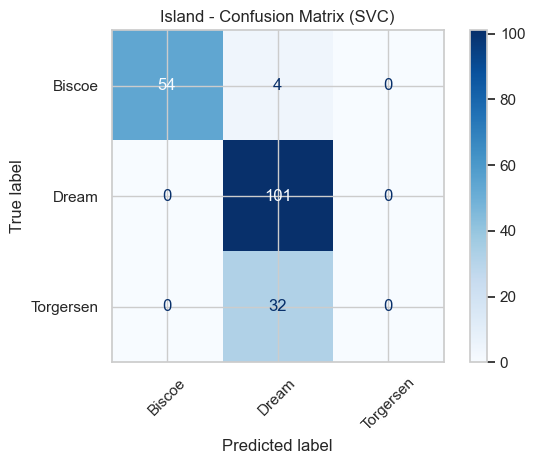


ISLAND - CLASSIFICATION REPORT: xgb_model
              precision    recall  f1-score   support

      Biscoe       1.00      0.93      0.96        58
       Dream       0.73      0.84      0.78       101
   Torgersen       0.24      0.16      0.19        32

    accuracy                           0.75       191
   macro avg       0.66      0.64      0.65       191
weighted avg       0.73      0.75      0.74       191


ISLAND - CONFUSION MATRIX: xgb_model


,Predicted Biscoe,Predicted Dream,Predicted Torgersen
Actual Biscoe,54,4,0
Actual Dream,0,85,16
Actual Torgersen,0,27,5


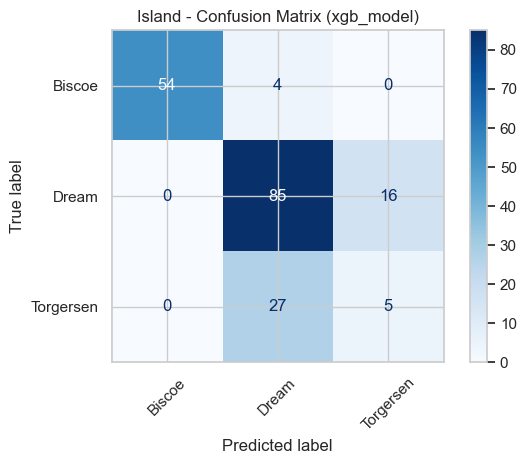


ISLAND - CLASSIFICATION REPORT: KNN
              precision    recall  f1-score   support

      Biscoe       1.00      0.93      0.96        58
       Dream       0.77      0.89      0.83       101
   Torgersen       0.45      0.28      0.35        32

    accuracy                           0.80       191
   macro avg       0.74      0.70      0.71       191
weighted avg       0.79      0.80      0.79       191


ISLAND - CONFUSION MATRIX: KNN


,Predicted Biscoe,Predicted Dream,Predicted Torgersen
Actual Biscoe,54,4,0
Actual Dream,0,90,11
Actual Torgersen,0,23,9


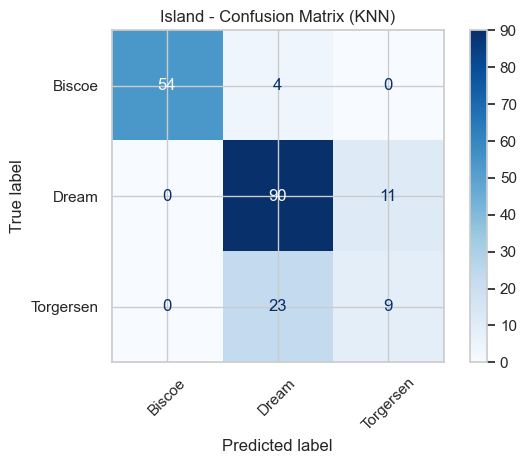


ISLAND - CLASSIFICATION REPORT: Random Forest
              precision    recall  f1-score   support

      Biscoe       1.00      0.93      0.96        58
       Dream       0.73      0.86      0.79       101
   Torgersen       0.22      0.12      0.16        32

    accuracy                           0.76       191
   macro avg       0.65      0.64      0.64       191
weighted avg       0.73      0.76      0.74       191


ISLAND - CONFUSION MATRIX: Random Forest


,Predicted Biscoe,Predicted Dream,Predicted Torgersen
Actual Biscoe,54,4,0
Actual Dream,0,87,14
Actual Torgersen,0,28,4


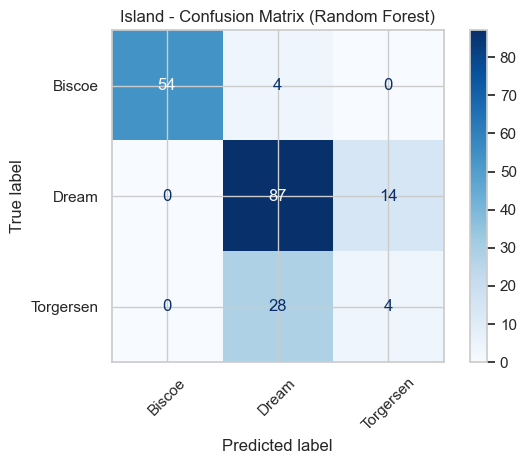

In [147]:


# Use the existing trained Island models
class_names = label_encoder.classes_
class_labels = np.arange(len(class_names))

for name, model in trained_models.items():
    y_pred = model.predict(X_test_processed)

    print(f"\n{'=' * 50}")
    print(f"ISLAND - CLASSIFICATION REPORT: {name}")
    print("=" * 50)

    print(classification_report(
        y_test_labels,
        y_pred,
        labels=class_labels,
        target_names=class_names,
        zero_division=0
    ))

    cm = confusion_matrix(
        y_test_labels,
        y_pred,
        labels=class_labels
    )

    cm_df = pd.DataFrame(
        cm,
        index=[f"Actual {c}" for c in class_names],
        columns=[f"Predicted {c}" for c in class_names]
    )

    print(f"\nISLAND - CONFUSION MATRIX: {name}")
    display(cm_df)

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=class_names
    )
    disp.plot(cmap="Blues", values_format="d")
    plt.title(f"Island - Confusion Matrix ({name})")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()



ISLAND - SVC
              precision    recall  f1-score   support

      Biscoe       1.00      0.93      0.96        58
       Dream       1.00      0.46      0.63       101
   Torgersen       0.35      1.00      0.52        32

    accuracy                           0.69       191
   macro avg       0.78      0.80      0.70       191
weighted avg       0.89      0.69      0.71       191



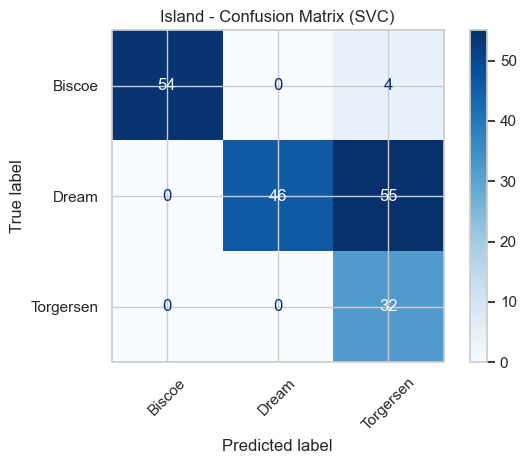


ISLAND - XGBoost
              precision    recall  f1-score   support

      Biscoe       1.00      0.93      0.96        58
       Dream       0.78      0.73      0.76       101
   Torgersen       0.33      0.44      0.38        32

    accuracy                           0.74       191
   macro avg       0.70      0.70      0.70       191
weighted avg       0.77      0.74      0.76       191



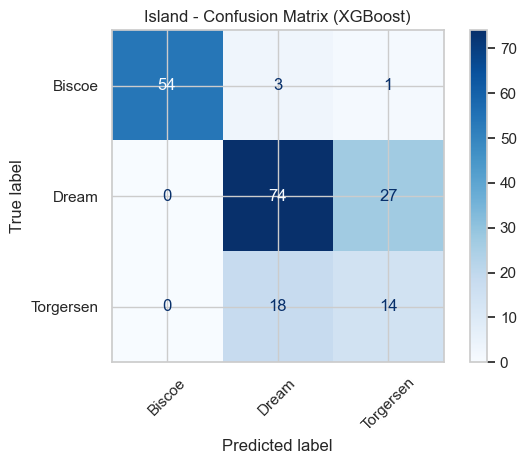


ISLAND - KNN
              precision    recall  f1-score   support

      Biscoe       1.00      0.93      0.96        58
       Dream       0.77      0.89      0.83       101
   Torgersen       0.45      0.28      0.35        32

    accuracy                           0.80       191
   macro avg       0.74      0.70      0.71       191
weighted avg       0.79      0.80      0.79       191



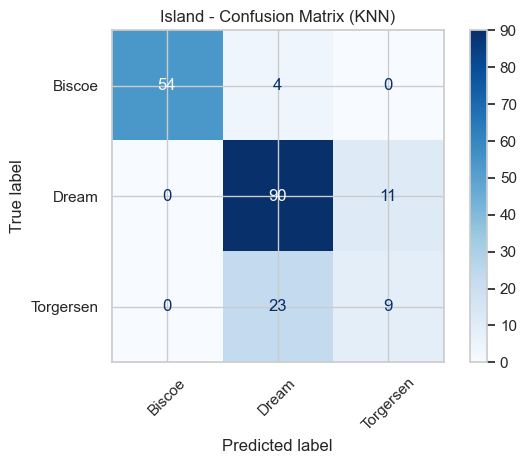


ISLAND - Random Forest
              precision    recall  f1-score   support

      Biscoe       1.00      0.93      0.96        58
       Dream       0.72      0.83      0.77       101
   Torgersen       0.19      0.12      0.15        32

    accuracy                           0.74       191
   macro avg       0.64      0.63      0.63       191
weighted avg       0.72      0.74      0.73       191



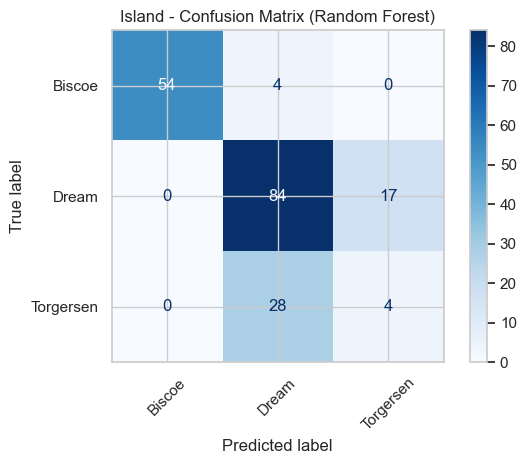

,Model,Accuracy,Precision,Recall,F1_Score
2,KNN,0.8010,0.7858,0.8010,0.7874
1,XGBoost,0.7435,0.7714,0.7435,0.7555
3,Random Forest,0.7435,0.7185,0.7435,0.7275
0,SVC,0.6911,0.8914,0.6911,0.7109


In [148]:
## Using class weights to improve

from sklearn.utils.class_weight import compute_sample_weight



# Calculate balanced weights from the training labels only
sample_weights = compute_sample_weight(
    class_weight="balanced",
    y=y_train_labels
)

models = {
    "SVC": SVC(
        C=1.0,
        kernel="rbf",
        class_weight="balanced",
        random_state=42
    ),

    "XGBoost": XGBClassifier(
        n_estimators=100,
        max_depth=4,
        learning_rate=0.1,
        objective="multi:softprob",
        num_class=len(label_encoder.classes_),
        eval_metric="mlogloss",
        random_state=42
    ),

    "KNN": KNeighborsClassifier(
        n_neighbors=5,
        weights="uniform",
        metric="minkowski"
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        class_weight="balanced",
        random_state=42
    )
}

trained_models = {}
results = []

for name, model in models.items():

    # XGBoost uses balanced sample weights
    if name == "XGBoost":
        model.fit(
            X_train_processed,
            y_train_labels,
            sample_weight=sample_weights
        )
    else:
        model.fit(X_train_processed, y_train_labels)

    y_pred = model.predict(X_test_processed)
    trained_models[name] = model

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test_labels, y_pred),
        "Precision": precision_score(
            y_test_labels, y_pred,
            average="weighted", zero_division=0
        ),
        "Recall": recall_score(
            y_test_labels, y_pred,
            average="weighted", zero_division=0
        ),
        "F1_Score": f1_score(
            y_test_labels, y_pred,
            average="weighted", zero_division=0
        )
    })

    print(f"\n{'=' * 50}")
    print(f"ISLAND - {name}")
    print("=" * 50)
    print(classification_report(
        y_test_labels,
        y_pred,
        labels=range(len(label_encoder.classes_)),
        target_names=label_encoder.classes_,
        zero_division=0
    ))

    ConfusionMatrixDisplay.from_predictions(
        y_test_labels,
        y_pred,
        labels=range(len(label_encoder.classes_)),
        display_labels=label_encoder.classes_,
        cmap="Blues",
        values_format="d"
    )
    plt.title(f"Island - Confusion Matrix ({name})")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

island_weighted_results = pd.DataFrame(results)
display(
    island_weighted_results.sort_values(
        "F1_Score", ascending=False
    ).round(4)
)


In [ ]:
## Predicting Sex
# even if we knew that it may not perform well, we wanted to see how the model performs with the current
# data
# Define columns
Numerical_cols = [
    'culmen_length_mm',
    'culmen_depth_mm',
    'flipper_length_mm',
    'body_mass_g'
]

Categorical_cols = ['island', 'species']
Target = 'sex'

# # Separate features and target
# X = Penguin_data[Numerical_cols + Categorical_cols]
# y = Penguin_data[[Target]]

# # Preprocess numerical and categorical features
# preprocessor = ColumnTransformer(
#     transformers=[
#         ('num', StandardScaler(), Numerical_cols),
#         ('cat', OneHotEncoder(handle_unknown='ignore',
#                               sparse_output=False), Categorical_cols)
#     ]
# )

# # Transform features
# X_processed = preprocessor.fit_transform(X)

# # One-hot encode the target column
# target_encoder = OneHotEncoder(sparse_output=False)
# y_encoded = target_encoder.fit_transform(y)

# # Convert transformed features into DataFrames
# X_processed_df = pd.DataFrame(
#     X_processed,
#     columns=preprocessor.get_feature_names_out(),
#     index=X.index
# )

# y_encoded_df = pd.DataFrame(
#     y_encoded,
#     columns=target_encoder.get_feature_names_out([Target]),
#     index=y.index
# )

# print("Processed features:")
# display(X_processed_df.head())

# print("One-hot encoded target:")
# display(y_encoded_df.head())


In [150]:
# Separate features and original target labels
X = Penguin_data[Numerical_cols + Categorical_cols]
y = Penguin_data[Target]

# Stratified train-test split (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=4,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

# Check species proportions
print("\nTraining set species proportions:")
display(y_train.value_counts(normalize=True).sort_index())

print("\nTesting set species proportions:")
display(y_test.value_counts(normalize=True).sort_index())


Training features: (760, 6)
Testing features: (191, 6)
Training target: (760,)
Testing target: (191,)

Training set species proportions:


Female    0.468421
Male      0.531579
Name: sex, dtype: float64


Testing set species proportions:


Female    0.465969
Male      0.534031
Name: sex, dtype: float64

In [ ]:

# Feature preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), Numerical_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore',
                              sparse_output=False), Categorical_cols)
    ]
)

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)



print("Processed X_train:", X_train_processed.shape)
print("Processed X_test:", X_test_processed.shape)

Processed X_train: (760, 10)
Processed X_test: (191, 10)
Encoded y_train: (760, 2)
Encoded y_test: (191, 2)


In [153]:

label_encoder = LabelEncoder()

y_train_labels = label_encoder.fit_transform(
    y_train.astype(str)
)

y_test_labels = label_encoder.transform(
    y_test.astype(str)
)

print("Sex mapping:")

for i, species in enumerate(label_encoder.classes_):
    print(f"{species} = {i}")


Sex mapping:
Female = 0
Male = 1


In [ ]:
# defining the models
models = {
    "SVC": SVC(
        C=1.0,
        kernel="rbf",
        random_state=42
    ),

    "xgb_model" : XGBClassifier(
        n_estimators=100,
        max_depth=4,
        learning_rate=0.1,
        objective="binary:logistic",
        eval_metric="mlogloss",
        random_state=42
    ),

    "KNN": KNeighborsClassifier(
        n_neighbors=5,
        weights="uniform",
        metric="minkowski"
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42
    )
}

results = []
trained_models = {}

for name, model in models.items():

    # Train the model
    model.fit(X_train_processed, y_train_labels)

    # Predict the test set
    y_pred = model.predict(X_test_processed)

    # Save the trained model
    trained_models[name] = model

    # Evaluate performance
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test_labels, y_pred),
        "Precision": precision_score(
            y_test_labels, y_pred,
            average="weighted", zero_division=0
        ),
        "Recall": recall_score(
            y_test_labels, y_pred,
            average="weighted", zero_division=0
        ),
        "F1_Score": f1_score(
            y_test_labels, y_pred,
            average="weighted", zero_division=0
        )
    })

results_df = pd.DataFrame(results)

display(
    results_df.sort_values(
        by="F1_Score",
        ascending=False
    ).reset_index(drop=True).round(4)
)


,Model,Accuracy,Precision,Recall,F1_Score
0,Random Forest,0.5340,0.5313,0.5340,0.5315
1,KNN,0.5131,0.5127,0.5131,0.5129
2,xgb_model,0.5183,0.5131,0.5183,0.5121
3,SVC,0.5288,0.5183,0.5288,0.5018



CLASSIFICATION REPORT: SVC
              precision    recall  f1-score   support

      Female       0.49      0.28      0.36        89
        Male       0.54      0.75      0.63       102

    accuracy                           0.53       191
   macro avg       0.52      0.51      0.49       191
weighted avg       0.52      0.53      0.50       191


CONFUSION MATRIX: SVC


,Predicted Female,Predicted Male
Actual Female,25,64
Actual Male,26,76


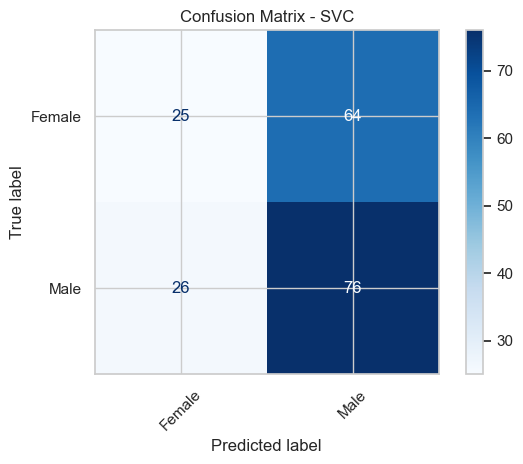


CLASSIFICATION REPORT: xgb_model
              precision    recall  f1-score   support

      Female       0.48      0.39      0.43        89
        Male       0.54      0.63      0.58       102

    accuracy                           0.52       191
   macro avg       0.51      0.51      0.51       191
weighted avg       0.51      0.52      0.51       191


CONFUSION MATRIX: xgb_model


,Predicted Female,Predicted Male
Actual Female,35,54
Actual Male,38,64


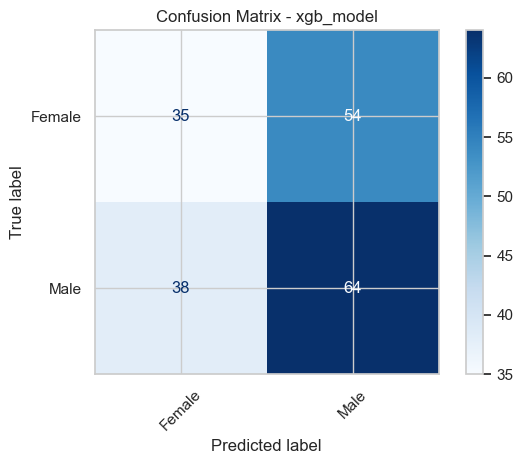


CLASSIFICATION REPORT: KNN
              precision    recall  f1-score   support

      Female       0.48      0.47      0.47        89
        Male       0.54      0.55      0.55       102

    accuracy                           0.51       191
   macro avg       0.51      0.51      0.51       191
weighted avg       0.51      0.51      0.51       191


CONFUSION MATRIX: KNN


,Predicted Female,Predicted Male
Actual Female,42,47
Actual Male,46,56


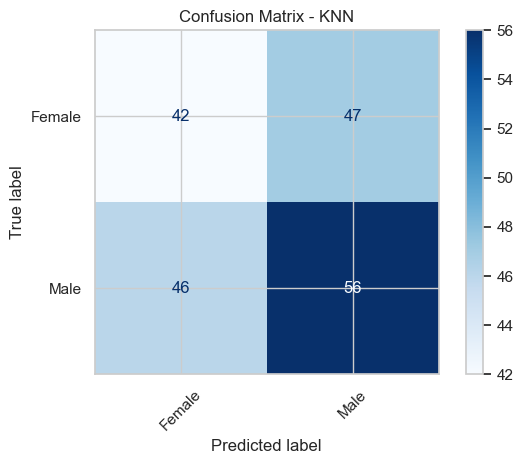


CLASSIFICATION REPORT: Random Forest
              precision    recall  f1-score   support

      Female       0.50      0.45      0.47        89
        Male       0.56      0.61      0.58       102

    accuracy                           0.53       191
   macro avg       0.53      0.53      0.53       191
weighted avg       0.53      0.53      0.53       191


CONFUSION MATRIX: Random Forest


,Predicted Female,Predicted Male
Actual Female,40,49
Actual Male,40,62


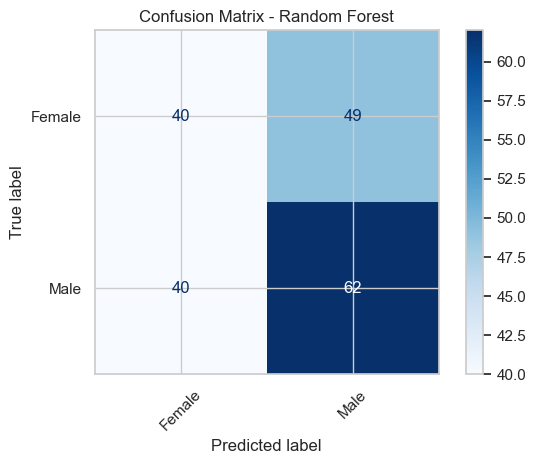

In [155]:

from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay


# Class names from your existing LabelEncoder
class_names = label_encoder.classes_
class_labels = np.arange(len(class_names))

# Evaluate each already-trained model
for name, model in trained_models.items():

    # Generate predictions using the existing trained model
    y_pred = model.predict(X_test_processed)

    # Classification report
    print("\n" + "=" * 60)
    print(f"CLASSIFICATION REPORT: {name}")
    print("=" * 60)

    print(classification_report(
        y_test_labels,
        y_pred,
        labels=class_labels,
        target_names=class_names,
        zero_division=0
    ))

    # Confusion matrix
    cm = confusion_matrix(
        y_test_labels,
        y_pred,
        labels=class_labels
    )

    cm_df = pd.DataFrame(
        cm,
        index=[f"Actual {c}" for c in class_names],
        columns=[f"Predicted {c}" for c in class_names]
    )

    print(f"\nCONFUSION MATRIX: {name}")
    display(cm_df)

    # Plot confusion matrix
    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=class_names
    )

    disp.plot(cmap="Blues", values_format="d")
    plt.title(f"Confusion Matrix - {name}")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()



SEX - SVC
              precision    recall  f1-score   support

      Female       0.51      0.55      0.53        89
        Male       0.58      0.54      0.56       102

    accuracy                           0.54       191
   macro avg       0.54      0.54      0.54       191
weighted avg       0.55      0.54      0.55       191



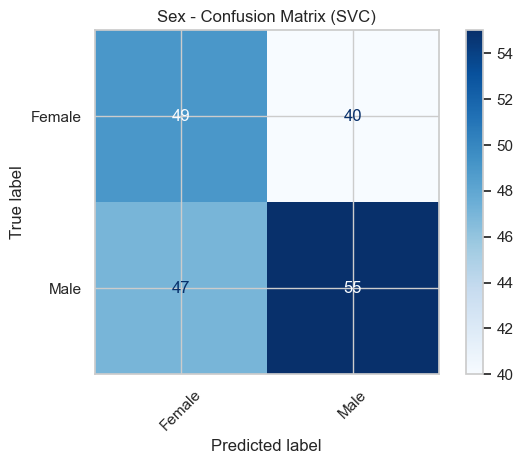


SEX - XGBoost
              precision    recall  f1-score   support

      Female       0.45      0.46      0.46        89
        Male       0.52      0.51      0.51       102

    accuracy                           0.49       191
   macro avg       0.49      0.49      0.49       191
weighted avg       0.49      0.49      0.49       191



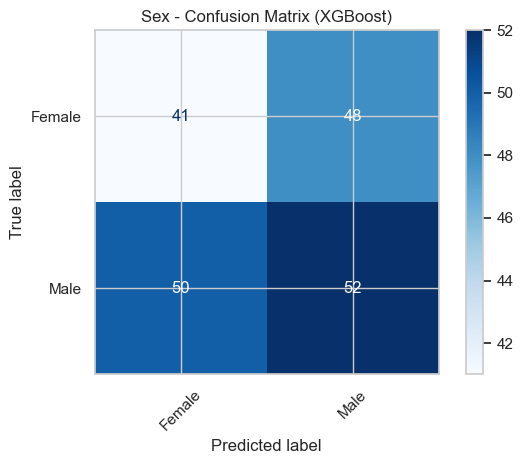


SEX - KNN
              precision    recall  f1-score   support

      Female       0.48      0.47      0.47        89
        Male       0.54      0.55      0.55       102

    accuracy                           0.51       191
   macro avg       0.51      0.51      0.51       191
weighted avg       0.51      0.51      0.51       191



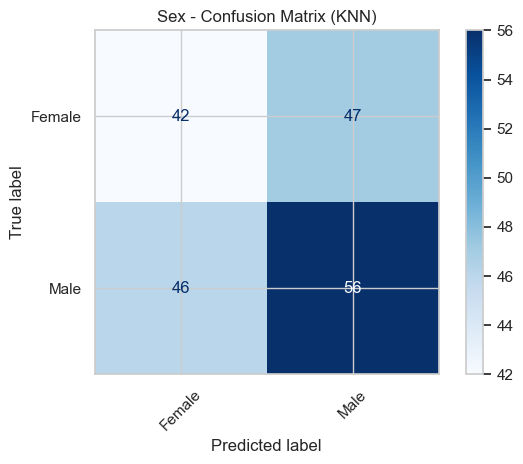


SEX - Random Forest
              precision    recall  f1-score   support

      Female       0.46      0.43      0.44        89
        Male       0.53      0.57      0.55       102

    accuracy                           0.50       191
   macro avg       0.50      0.50      0.50       191
weighted avg       0.50      0.50      0.50       191



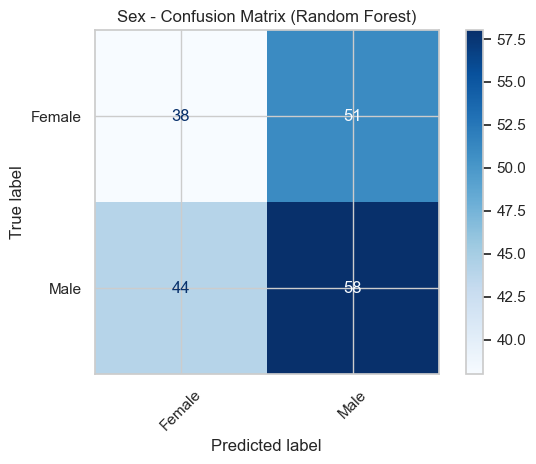

,Model,Accuracy,Precision,Recall,F1_Score
0,SVC,0.5445,0.5470,0.5445,0.5450
2,KNN,0.5131,0.5127,0.5131,0.5129
3,Random Forest,0.5026,0.5001,0.5026,0.5007
1,XGBoost,0.4869,0.4876,0.4869,0.4872


In [ ]:
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, ConfusionMatrixDisplay
)
from xgboost import XGBClassifier
import pandas as pd
import matplotlib.pyplot as plt
# perform balanced weight training model
# Calculate balanced weights from the training labels only
sample_weights = compute_sample_weight(
    class_weight="balanced",
    y=y_train_labels
)

models = {
    "SVC": SVC(
        C=1.0,
        kernel="rbf",
        class_weight="balanced",
        random_state=42
    ),

    "XGBoost": XGBClassifier(
        n_estimators=100,
        max_depth=4,
        learning_rate=0.1,
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=42
    ),

    "KNN": KNeighborsClassifier(
        n_neighbors=5,
        weights="uniform",
        metric="minkowski"
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        class_weight="balanced",
        random_state=42
    )
}

trained_models = {}
results = []

for name, model in models.items():

    # XGBoost uses balanced sample weights
    if name == "XGBoost":
        model.fit(
            X_train_processed,
            y_train_labels,
            sample_weight=sample_weights
        )
    else:
        model.fit(X_train_processed, y_train_labels)

    y_pred = model.predict(X_test_processed)
    trained_models[name] = model

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test_labels, y_pred),
        "Precision": precision_score(
            y_test_labels, y_pred,
            average="weighted", zero_division=0
        ),
        "Recall": recall_score(
            y_test_labels, y_pred,
            average="weighted", zero_division=0
        ),
        "F1_Score": f1_score(
            y_test_labels, y_pred,
            average="weighted", zero_division=0
        )
    })

    print(f"\n{'=' * 50}")
    print(f"SEX - {name}")
    print("=" * 50)
    print(classification_report(
        y_test_labels,
        y_pred,
        labels=range(len(label_encoder.classes_)),
        target_names=label_encoder.classes_,
        zero_division=0
    ))

    ConfusionMatrixDisplay.from_predictions(
        y_test_labels,
        y_pred,
        labels=range(len(label_encoder.classes_)),
        display_labels=label_encoder.classes_,
        cmap="Blues",
        values_format="d"
    )
    plt.title(f"Sex - Confusion Matrix ({name})")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

sex_weighted_results = pd.DataFrame(results)
display(
    sex_weighted_results.sort_values(
        "F1_Score", ascending=False
    ).round(4)
)
